# Inference speed-up from restricted context: EmbeddingGemma2 (320 ms window) vs Whisper (30 s chunk)

The Gemma model is restricted to one window of `WIN = 5120` samples (320 ms): `EmbeddingGemma2Eval.ipynb` classifies
`(B, 5120)` windows with `classifier(embed(x))`. The Whisper model (`WDPWhisperEmbModelV2`) always encodes a full 30 s chunk
(padded to 3000 mel frames -> 1500 encoder frames), which yields `L = 188` labelled 320 ms windows (window 16 / step 8 frames).
This notebook measures inference throughput of both in labelled 320 ms windows per second and the resulting speed-up.

Model setup as in the Eval notebook (LoRA r=16/α=32 on q/k/v/o, unmerged; 128-d head, 5-class classifier), no grad.
Inputs are random noise: speed does not depend on content. 2 warm-up + median of 5 timed calls, feature extraction included.
Absolute numbers depend on the device; the ratio is what matters.

In [1]:
import os, sys, time, inspect, platform
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor, WhisperProcessor
from peft import LoraConfig, get_peft_model

DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
MID = "google/embeddinggemma-2"
SR = 16_000
WIN = 5120                            # the only window the Gemma model ever sees (320 ms)
NUM_CLASSES, PROJ_DIM = 5, 128
GEMMA_B = [16, 32, 64, 128, 256]      # windows per forward (64 = Eval)
WHISPER_B = [1, 2, 4, 8]              # 30 s chunks per forward
L = 188                               # labelled windows per Whisper chunk
WARM, STEPS = 2, 5

def sync():
    if DEV == "cuda": torch.cuda.synchronize()
    elif DEV == "mps": torch.mps.synchronize()

def free():
    if DEV == "cuda": torch.cuda.empty_cache()
    elif DEV == "mps": torch.mps.empty_cache()

def timed(fn):
    ts = []
    for i in range(WARM + STEPS):
        sync(); t0 = time.perf_counter()
        with torch.no_grad(): fn()
        sync()
        if i >= WARM: ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def sweep(fn, batches, per_call):
    rows = []
    for B in batches:
        try:
            s = timed(lambda: fn(B))
        except RuntimeError as e:                  # out of memory: larger B won't fit either
            print(f"B {B}: {str(e).splitlines()[0][:100]}"); free(); break
        free()
        rows.append(dict(B=B, call_s=s, windows_per_s=B * per_call / s))
        print(f"B {B:4d}  {s:6.3f}s  {B * per_call / s:8.1f} windows/s")
    return pd.DataFrame(rows)

print(DEV, platform.processor() or platform.machine(), "torch", torch.__version__)

W1126 14:36:36.929000 73690 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


mps arm torch 2.14.1


In [2]:
# ---- Gemma: model as in EmbeddingGemma2Eval.ipynb ----
cfg = AutoConfig.from_pretrained(MID); cfg.vision_config = None
base = AutoModel.from_pretrained(MID, config=cfg, torch_dtype=torch.float32)
audio_tower = next(m for m in base.modules() if type(m).__name__.endswith("AudioModel")); del base
feature_extractor = AutoFeatureExtractor.from_pretrained(MID)
TOWER_TAKES_MASK = len(inspect.signature(audio_tower.forward).parameters) > 1
PROJ = {"q_proj", "k_proj", "v_proj", "o_proj"}
targets = [n for n, m in audio_tower.named_modules() if isinstance(m, nn.Linear) and PROJ & set(n.split("."))]
audio_tower = get_peft_model(audio_tower, LoraConfig(r=16, lora_alpha=32, target_modules=targets))

def run_tower(tower, x):
    dev = next(tower.parameters()).device
    f = feature_extractor(list(x.detach().cpu().numpy()), sampling_rate=SR, return_tensors="pt")
    feats = f["input_features"].to(dev)
    out = tower(feats, f["input_features_mask"].to(dev)) if TOWER_TAKES_MASK else tower(feats)
    return out[0] if isinstance(out, tuple) else out.last_hidden_state

class WDPModel(nn.Module):
    def __init__(self, tower, num_classes, proj_dim=PROJ_DIM, p_drop=0.1):
        super().__init__()
        self.encoder = tower
        with torch.no_grad():
            d = run_tower(tower, torch.zeros(1, WIN)).shape[-1]
        self.head_embedding = nn.Linear(d, proj_dim)
        self.classifier = nn.Sequential(nn.Dropout(p_drop), nn.Linear(proj_dim, num_classes))

    def embed(self, x):
        return self.head_embedding(run_tower(self.encoder, x).mean(1).float())

    def forward(self, x):
        z = self.embed(x)
        return {"classifications": self.classifier(z), "embeddings": F.normalize(z, dim=-1)}

clf = WDPModel(audio_tower, NUM_CLASSES).to(DEV).eval()
with torch.no_grad():
    print(f"WIN {WIN} samples = {1000*WIN/SR:.0f} ms -> {run_tower(clf.encoder, torch.zeros(1, WIN)).shape[1]} tower tokens")

gemma = sweep(lambda B: clf(torch.randn(B, WIN) * 0.1), GEMMA_B, 1)
del clf, audio_tower; free()

Loading weights:   0%|          | 0/1165 [00:00<?, ?it/s]

WIN 5120 samples = 320 ms -> 8 tower tokens


B   16   0.083s     193.8 windows/s


B   32   0.153s     209.2 windows/s


B   64   0.291s     219.8 windows/s


B  128   0.570s     224.6 windows/s


B  256   1.180s     217.0 windows/s


In [3]:
# ---- Whisper: 30 s chunks, WDPWhisperEmbModelV2 ----
sys.path.insert(0, os.path.abspath(".."))
from lib_phmm.model import WDPWhisperEmbModelV2, lora_encoder
proc = WhisperProcessor.from_pretrained("openai/whisper-small")
wm = WDPWhisperEmbModelV2(lora_encoder()).to(DEV).eval()

def whisper_call(B):
    f = proc.feature_extractor([np.random.randn(SR * 30).astype(np.float32) * 0.1 for _ in range(B)],
                               sampling_rate=SR, return_tensors="pt", return_attention_mask=True)
    wm(f["input_features"].to(DEV), input_mask=f["attention_mask"].float().to(DEV))

whisper = sweep(whisper_call, WHISPER_B, L)

Loading base model: openai/whisper-small


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

B    1   0.225s     835.1 windows/s


B    2   0.460s     816.9 windows/s


B    4   0.866s     868.0 windows/s


B    8   1.780s     845.0 windows/s


## Results

Throughput in labelled 320 ms windows per second. Speed-up = best Gemma / best Whisper throughput.

In [4]:
bg, bw = gemma.loc[gemma.windows_per_s.idxmax()], whisper.loc[whisper.windows_per_s.idxmax()]
display(gemma.round(3)); display(whisper.round(3))
pd.DataFrame([dict(gemma_best_B=int(bg.B), gemma_windows_per_s=bg.windows_per_s,
                   whisper_best_B=int(bw.B), whisper_windows_per_s=bw.windows_per_s,
                   speedup=bg.windows_per_s / bw.windows_per_s)]).round(2)

,B,call_s,windows_per_s
0,16,0.083,193.838
1,32,0.153,209.240
2,64,0.291,219.812
3,128,0.570,224.648
4,256,1.180,217.006


,B,call_s,windows_per_s
0,1,0.225,835.087
1,2,0.460,816.941
2,4,0.866,867.991
3,8,1.780,845.035


,gemma_best_B,gemma_windows_per_s,whisper_best_B,whisper_windows_per_s,speedup
0,128,224.65,4,867.99,0.26


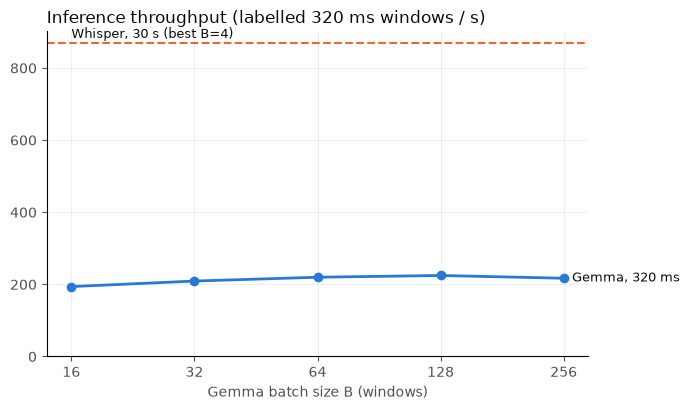

In [5]:
GEMMA, WHISPER, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(gemma.B, gemma.windows_per_s, color=GEMMA, lw=2, marker="o", ms=6)
ax.annotate("Gemma, 320 ms", (gemma.B.iloc[-1], gemma.windows_per_s.iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", color=INK, fontsize=9)
ax.axhline(bw.windows_per_s, color=WHISPER, lw=1.5, ls="--")
ax.annotate(f"Whisper, 30 s (best B={int(bw.B)})", (gemma.B.iloc[0], bw.windows_per_s), xytext=(0, 4),
            textcoords="offset points", color=INK, fontsize=9)
ax.set_xscale("log", base=2); ax.set_xticks(gemma.B); ax.set_xticklabels(gemma.B)
ax.set_xlabel("Gemma batch size B (windows)", color=MUTED); ax.set_ylim(bottom=0)
ax.set_title("Inference throughput (labelled 320 ms windows / s)", loc="left", color=INK)
ax.grid(alpha=0.25, lw=0.6); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(colors=MUTED)
plt.tight_layout(); plt.show()